In [4]:
import torchvision.transforms as transforms

Using device: cuda

--- DDPM PHASE 3: CLASSIFICATION ANALYSIS START ---
Loading baseline data
Original data loaded: Train: (4800, 256, 256, 3), Val: (1600, 256, 256, 3), Test: (1600, 256, 256, 3)
Loading generated data from results/diffusion/
Synthetic data loaded: (800, 128, 128, 3), Classes: [0 1 4 7]

DDPM AUGMENTATION: Creating augmented dataset
Original training class distribution: {np.uint8(0): 297, np.uint8(1): 491, np.uint8(2): 740, np.uint8(3): 548, np.uint8(4): 94, np.uint8(5): 543, np.uint8(6): 482, np.uint8(7): 704, np.uint8(8): 380, np.uint8(9): 521}
Resizing 4800 original images (256x256 -> 128x128)...


Resizing Original Data: 100%|██████████| 4800/4800 [00:04<00:00, 1176.92it/s]


Original data resized from (4800, 256, 256, 3) to (4800, 128, 128, 3)
Synthetic data shape: (800, 128, 128, 3)
Augmented training class distribution: {np.int64(0): 497, np.int64(1): 691, np.int64(2): 740, np.int64(3): 548, np.int64(4): 294, np.int64(5): 543, np.int64(6): 482, np.int64(7): 904, np.int64(8): 380, np.int64(9): 521}

Minority class improvement for DDPM augmented set:
Class 0: 297 → 497 (+67.3%)
Class 1: 491 → 691 (+40.7%)
Class 4: 94 → 294 (+212.8%)
Class 7: 704 → 904 (+28.4%)

TRAINING DIFFUSION CLASSIFIER
Training parameters: Batch size=8, Epochs=25, LR=0.001
Training samples: 5600
Model parameters: 6,964,106

Epoch 1/25
------------------------------


Validation: 100%|██████████| 200/200 [00:05<00:00, 33.38it/s]


Train Loss: 1.6979, Train Acc: 0.3879
Val Loss: 1.7853, Val Acc: 0.4406
New best validation accuracy: 0.4406

Epoch 2/25
------------------------------


Validation: 100%|██████████| 200/200 [00:05<00:00, 34.55it/s]


... (45 outputs left out)

Validation: 100%|██████████| 200/200 [00:05<00:00, 36.02it/s]


Train Loss: 0.2982, Train Acc: 0.8996
Val Loss: 0.7250, Val Acc: 0.7769

EVALUATING DIFFUSION MODEL PERFORMANCE


Testing: 100%|██████████| 200/200 [00:05<00:00, 36.07it/s]


Overall Test Accuracy: 0.7869

DDPM FOCUS CLASS PERFORMANCE ([0, 1, 4, 7]):
Class 0 (Disturbed Galaxies): F1-score: 0.395
Class 1 (Merging Galaxies): F1-score: 0.750
Class 4 (Cigar Shaped Smooth Galaxies): F1-score: 0.675
Class 7 (Unbarred Loose Spiral Galaxies): F1-score: 0.681
Average F1-score for DDPM focus classes: 0.625

Full Classification Report:
                                  precision    recall  f1-score   support

              Disturbed Galaxies       0.33      0.48      0.40        99
                Merging Galaxies       0.90      0.64      0.75       163
           Round Smooth Galaxies       0.89      0.91      0.90       246
In-between Round Smooth Galaxies       0.91      0.92      0.92       183
    Cigar Shaped Smooth Galaxies       0.57      0.84      0.68        31
          Barred Spiral Galaxies       0.84      0.75      0.79       181
  Unbarred Tight Spiral Galaxies       0.79      0.73      0.75       161
  Unbarred Loose Spiral Galaxies       0.68      0.

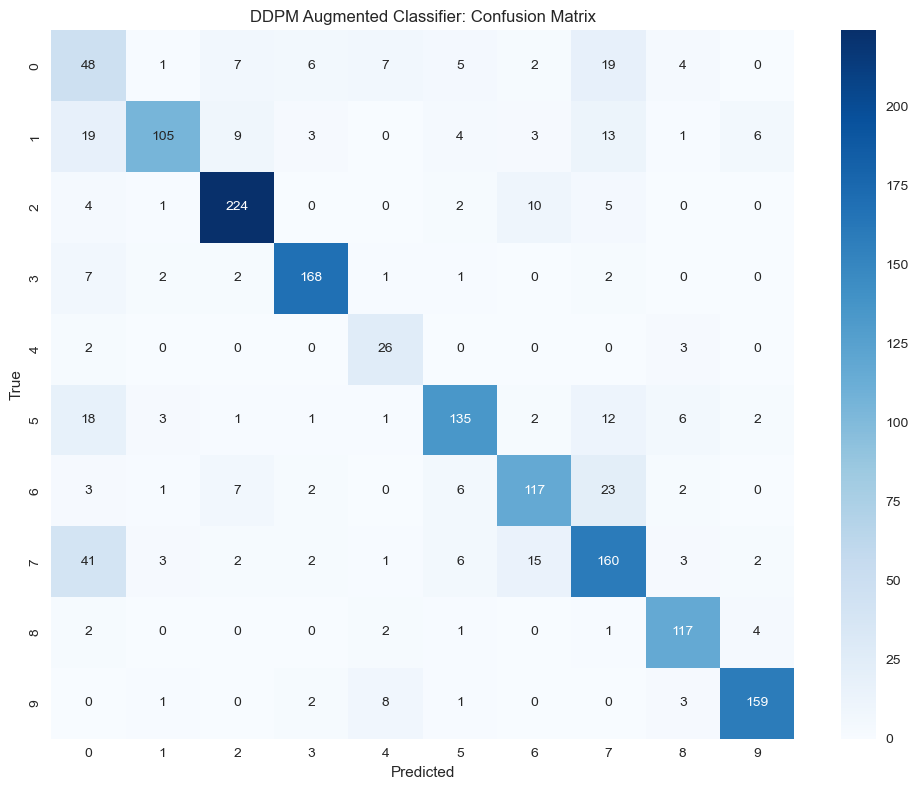


--- DDPM PHASE 3 ANALYSIS COMPLETE. ---


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
# Importing specific weight constant for stable DenseNet loading
from torchvision.models import densenet121, DenseNet121_Weights 
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import json
import os
from datetime import datetime
from collections import Counter
from tqdm import tqdm
import gc
from PIL import Image


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

#  Utility Functions 

class Galaxy10Dataset(Dataset):
    def __init__(self, images, labels, transform=None):
        if images.dtype == np.uint8:
            self.images = images
        elif np.issubtype(images.dtype, np.floating) and images.max() <= 1.0:
             self.images = (images * 255).astype(np.uint8)
        else:
             self.images = images.astype(np.uint8) 

        self.labels = labels.astype(np.int64)
        self.transform = transform
        
    def __len__(self):
        return len(self.images)
    
    def __getitem__(self, idx):
        image = self.images[idx]
        label = self.labels[idx]
        
        if self.transform:
            image = Image.fromarray(image)
            image = self.transform(image)
        else:
            image = torch.from_numpy(image.astype(np.float32) / 255.0).permute(2, 0, 1)
        
        return image, torch.tensor(label, dtype=torch.long)

class BaselineClassifier(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        try:
            # Use weights object for stability
            self.densenet = densenet121(weights=DenseNet121_Weights.IMAGENET1K_V1) 
        except AttributeError:
             self.densenet = densenet121(pretrained=True) 
        self.densenet.classifier = nn.Linear(self.densenet.classifier.in_features, num_classes)
    
    def forward(self, x):
        return self.densenet(x)

def load_baseline_data():
    print("Loading baseline data")
    data_dir = 'data/processed'
    X_train = np.load(f'{data_dir}/X_train.npy')
    X_val = np.load(f'{data_dir}/X_val.npy')
    X_test = np.load(f'{data_dir}/X_test.npy')
    y_train = np.load(f'{data_dir}/y_train.npy')
    y_val = np.load(f'{data_dir}/y_val.npy')
    y_test = np.load(f'{data_dir}/y_test.npy')
    
    try:
        with open(f'{data_dir}/data_info.json', 'r') as f:
            data_info = json.load(f)
    except FileNotFoundError:
        data_info = {'class_names': [
            'Disturbed Galaxies', 'Merging Galaxies', 'Round Smooth Galaxies',
            'In-between Round Smooth Galaxies', 'Cigar Shaped Smooth Galaxies',  
            'Barred Spiral Galaxies', 'Unbarred Tight Spiral Galaxies',
            'Unbarred Loose Spiral Galaxies', 'Edge-on Galaxies without Bulge',
            'Edge-on Galaxies with Bulge'
        ]}
    
    print(f"Original data loaded: Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")
    
    return X_train, X_val, X_test, y_train, y_val, y_test, data_info

def load_synthetic_data(source='diffusion'):
    print(f"Loading generated data from results/{source}/")
    
    if not os.path.exists(f'results/{source}/synthetic_images.npy'):
        raise FileNotFoundError(f"Cannot find synthetic_images.npy in results/{source}/. Ensure DDPM Step 2 was run successfully.")
    
    synthetic_images = np.load(f'results/{source}/synthetic_images.npy')
    synthetic_labels = np.load(f'results/{source}/synthetic_labels.npy')
    print(f"Synthetic data loaded: {synthetic_images.shape}, Classes: {np.unique(synthetic_labels)}")
    return synthetic_images, synthetic_labels

def load_baseline_results():
    try:
        with open('results/baseline/baseline_metrics.json', 'r') as f:
            baseline_results = json.load(f)
        return baseline_results
    except FileNotFoundError:
        print("Baseline results not found.")
        return None

#DDPM Augmentation and Training 

def create_augmented_dataset(X_train, y_train, synthetic_images, synthetic_labels, minority_classes):
    print("\nDDPM AUGMENTATION: Creating augmented dataset")
    
    #  DDPM STRATEGIC CLASSES 
    MINORITY_CLASSES_DDPM = [0, 1, 4, 7] 
    
    original_counts = Counter(y_train)
    print(f"Original training class distribution: {dict(sorted(original_counts.items()))}")
    
    # Resizing original data to match 128x128 synthetic data
    X_train_resized = []
    print(f"Resizing {X_train.shape[0]} original images (256x256 -> 128x128)...")
    for img in tqdm(X_train, desc="Resizing Original Data"):
        img_pil = Image.fromarray(img)
        img_resized = img_pil.resize((128, 128))
        X_train_resized.append(np.array(img_resized))
    
    X_train_resized = np.array(X_train_resized)
    print(f"Original data resized from {X_train.shape} to {X_train_resized.shape}")
    print(f"Synthetic data shape: {synthetic_images.shape}")
    
    augmented_images = np.concatenate([X_train_resized, synthetic_images], axis=0)
    augmented_labels = np.concatenate([y_train, synthetic_labels], axis=0)
    
    augmented_counts = Counter(augmented_labels)
    print(f"Augmented training class distribution: {dict(sorted(augmented_counts.items()))}")
    
    print("\nMinority class improvement for DDPM augmented set:")
    for class_id in MINORITY_CLASSES_DDPM:
        original_count = original_counts.get(class_id, 0)
        augmented_count = augmented_counts.get(class_id, 0)
        improvement = ((augmented_count - original_count) / original_count * 100) if original_count > 0 else 0
        print(f"Class {class_id}: {original_count} → {augmented_count} (+{improvement:.1f}%)")
    
    return augmented_images, augmented_labels


def train_augmented_classifier(X_train_aug, y_train_aug, X_val, y_val, experiment_name="diffusion"):
    print(f"\nTRAINING {experiment_name.upper()} CLASSIFIER")
    
    BATCH_SIZE = 8
    EPOCHS = 25
    LEARNING_RATE = 0.001
    
    print(f"Training parameters: Batch size={BATCH_SIZE}, Epochs={EPOCHS}, LR={LEARNING_RATE}")
    print(f"Training samples: {len(X_train_aug)}")
    
    train_transform = transforms.Compose([
        transforms.Resize((128, 128)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(10),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    
    val_test_transform = transforms.Compose([
        transforms.Resize((128, 128)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    
    train_dataset = Galaxy10Dataset(X_train_aug, y_train_aug, transform=train_transform)
    val_dataset = Galaxy10Dataset(X_val, y_val, transform=val_test_transform)
    
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=False)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=False)
    
    model = BaselineClassifier(num_classes=10).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)
    
    print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")
    
    train_losses, val_losses = [], []
    train_accuracies, val_accuracies = [], []
    best_val_accuracy = 0.0
    best_model_state = None
    
    for epoch in range(EPOCHS):
        print(f'\nEpoch {epoch+1}/{EPOCHS}')
        
        
        # Training
        model.train()
        running_loss = 0.0
        correct_predictions = 0
        total_predictions = 0
        
        
        for images, labels in tqdm(train_loader, desc="Training"):
      
            images, labels = images.to(device), labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total_predictions += labels.size(0)
            correct_predictions += (predicted == labels).sum().item()
            
        
        train_loss = running_loss / len(train_loader)
        train_accuracy = correct_predictions / total_predictions
        train_losses.append(train_loss)
        train_accuracies.append(train_accuracy)
        
        # Validation
        model.eval()
        val_running_loss = 0.0
        val_correct = 0
        val_total = 0
        
        with torch.no_grad():
            for images, labels in tqdm(val_loader, desc="Validation"):
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                
                val_running_loss += loss.item()
                _, predicted = torch.max(outputs.data, 1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()
        
        val_loss = val_running_loss / len(val_loader)
        val_accuracy = val_correct / val_total
        val_losses.append(val_loss)
        val_accuracies.append(val_accuracy)
        
        scheduler.step()
        
        print(f'Train Loss: {train_loss:.4f}, Train Acc: {train_accuracy:.4f}')
        print(f'Val Loss: {val_loss:.4f}, Val Acc: {val_accuracy:.4f}')
        
        # Save best model
        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            best_model_state = model.state_dict().copy()
            print(f'New best validation accuracy: {val_accuracy:.4f}')
    
    # Load best model
    if best_model_state:
        model.load_state_dict(best_model_state)
    
    return model, {
        'train_losses': train_losses,
        'val_losses': val_losses,
        'train_accuracies': train_accuracies,
        'val_accuracies': val_accuracies,
        'best_val_accuracy': best_val_accuracy,
        'experiment_name': experiment_name
    }


def evaluate_model_performance(model, X_test, y_test, class_names, experiment_name="diffusion"):
    
    # DDPM STRATEGIC CLASSES 
    FOCUS_CLASSES = [0, 1, 4, 7]

    print(f"\nEVALUATING {experiment_name.upper()} MODEL PERFORMANCE")
    
    test_transform = transforms.Compose([
        transforms.Resize((128, 128)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    
    test_dataset = Galaxy10Dataset(X_test, y_test, transform=test_transform)
    test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False, num_workers=0)
    
    # Predict
    model.eval()
    all_predictions = []
    all_labels = []
    
    with torch.no_grad():
        for images, labels in tqdm(test_loader, desc="Testing"):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            
            all_predictions.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    
    y_true = np.array(all_labels)
    y_pred = np.array(all_predictions)
    
    # Overall accuracy
    overall_accuracy = np.mean(y_true == y_pred)
    print(f"Overall Test Accuracy: {overall_accuracy:.4f}")
    
    class_report = classification_report(
        y_true, y_pred, 
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )
    
    # Report focus class performance
    focus_f1_scores = []
    
    print(f"\nDDPM FOCUS CLASS PERFORMANCE ({FOCUS_CLASSES}):")
    
    for class_id in FOCUS_CLASSES:
        if class_id < len(class_names):
            class_name = class_names[class_id]
            f1 = class_report[class_name]['f1-score']
            focus_f1_scores.append(f1)
            print(f"Class {class_id} ({class_name}): F1-score: {f1:.3f}")
            
    avg_focus_f1 = np.mean(focus_f1_scores)
    cigar_f1 = class_report[class_names[4]]['f1-score']
    
    print(f"Average F1-score for DDPM focus classes: {avg_focus_f1:.3f}")
    
    # Full report output
    print("\nFull Classification Report:")
    print(classification_report(y_true, y_pred, target_names=class_names))
    
    
    # to Save the results
    os.makedirs('results/diffusion', exist_ok=True)
    diffusion_metrics = {
        'overall_accuracy': overall_accuracy,
        'avg_focus_f1': avg_focus_f1,
        'cigar_f1': cigar_f1, 
        'class_report': class_report,
        'minority_f1_scores': focus_f1_scores
    }
    
    with open('results/diffusion/diffusion_augmented_metrics.json', 'w') as f:
        json.dump(diffusion_metrics, f, indent=2, default=str)
        
    torch.save(model.state_dict(), 'results/diffusion/diffusion_augmented_model.pth')
    print("\nDDPM classification results saved to results/diffusion/")
    
    plt.figure(figsize=(10, 8))
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=range(10), yticklabels=range(10))
    plt.title('DDPM Augmented Classifier: Confusion Matrix')
    plt.ylabel('True')
    plt.xlabel('Predicted')
    plt.tight_layout()
    plt.show()

    return diffusion_metrics

def run_phase3_analysis():
    
    print("\n--- DDPM PHASE 3: CLASSIFICATION ANALYSIS START ---")
    
    #  Load Data
    X_train, X_val, X_test, y_train, y_val, y_test, data_info = load_baseline_data()
    synthetic_images, synthetic_labels = load_synthetic_data('diffusion')
    
    #  to create Augmented Dataset
    X_train_aug, y_train_aug = create_augmented_dataset(
        X_train, y_train, synthetic_images, synthetic_labels, [0, 1, 4, 7]
    )
    
    #  to Train Classifier
    ddpm_model, ddpm_training_results = train_augmented_classifier(
        X_train_aug, y_train_aug, X_val, y_val, "diffusion"
    )
    
    #  Evaluate Performance
    ddpm_metrics = evaluate_model_performance(
        ddpm_model, X_test, y_test, data_info['class_names'], "diffusion"
    )
    
    print("\nDDPM PHASE 3 ANALYSIS COMPLETE. ")
    
    return ddpm_model, ddpm_metrics



ddpm_model, ddpm_metrics = run_phase3_analysis()
